# Week 7 Homework: Hands-On ML Solution Data Visualizations
**Team: Group 5 | FinMark ML Project**

This notebook revisits the team's finalized Milestone 1 Exploratory Data Analysis and builds on it with additional NumPy-based numerical analysis and Matplotlib / Seaborn visualizations, as required for the Week 7 homework activity. The visualizations and interpretations developed here are intended to support Milestone 2.

**Datasets used:** the finalized Milestone 1 cleaned datasets —
- `customer_demographics_group5_cleaned.csv`
- `customer_transactions_group5_cleaned.csv`
- `social_media_interactions_group5_cleaned.csv`

**Libraries used:** Pandas, NumPy, Matplotlib, Seaborn, SciPy (for skewness/kurtosis).

## 1. Setup and Load the Finalized Milestone 1 Cleaned Datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10
PALETTE = sns.color_palette("mako", 8)
CAT_PALETTE = sns.color_palette("Set2")

In [2]:
demo = pd.read_csv('customer_demographics_group5_cleaned.csv')
trans = pd.read_csv('customer_transactions_group5_cleaned.csv')
social = pd.read_csv('social_media_interactions_group5_cleaned.csv')

demo['SignupDate'] = pd.to_datetime(demo['SignupDate'], errors='coerce')
trans['TransactionDate'] = pd.to_datetime(trans['TransactionDate'], errors='coerce')
social['InteractionDate'] = pd.to_datetime(social['InteractionDate'], errors='coerce')

print("Demographics:", demo.shape)
print("Transactions:", trans.shape)
print("Social Media :", social.shape)

Demographics: (3023, 6)
Transactions: (3014, 6)
Social Media : (3019, 6)


## 2. Extended Numerical Analysis Using NumPy

Milestone 1 already reported mean, median, mode, standard deviation, variance, and range for Age and transaction Amount. Here NumPy is used to go further: quartiles, interquartile range (IQR), coefficient of variation, skewness, kurtosis, and a z-score based outlier check, computed directly with `numpy` and `scipy.stats`.

In [3]:
def numpy_summary(arr, label):
    arr = np.asarray(arr, dtype=float)
    summary = {
        'n': arr.size,
        'mean': np.mean(arr),
        'median': np.median(arr),
        'std': np.std(arr, ddof=1),
        'var': np.var(arr, ddof=1),
        'min': np.min(arr),
        'max': np.max(arr),
        'range': np.ptp(arr),
        'p25': np.percentile(arr, 25),
        'p75': np.percentile(arr, 75),
        'iqr': np.percentile(arr, 75) - np.percentile(arr, 25),
        'skewness': stats.skew(arr),
        'kurtosis': stats.kurtosis(arr),
        'cv': np.std(arr, ddof=1) / np.mean(arr) if np.mean(arr) != 0 else np.nan,
    }
    print(f"\n--- NumPy extended summary: {label} ---")
    for k, v in summary.items():
        print(f"  {k:10s}: {v:,.3f}" if isinstance(v, float) else f"  {k:10s}: {v}")
    return summary

age_summary = numpy_summary(demo['Age'], "Age (Demographics)")
amount_summary = numpy_summary(trans['Amount'], "Transaction Amount")

# Transactions-per-customer distribution (NumPy, derived metric)
tpc = trans.groupby('CustomerID').size().values
tpc_summary = numpy_summary(tpc, "Transactions per Customer")


--- NumPy extended summary: Age (Demographics) ---
  n         : 3023
  mean      : 44.689
  median    : 45.000
  std       : 14.424
  var       : 208.054
  min       : 18.000
  max       : 70.000
  range     : 52.000
  p25       : 34.000
  p75       : 57.000
  iqr       : 23.000
  skewness  : -0.076
  kurtosis  : -0.967
  cv        : 0.323

--- NumPy extended summary: Transaction Amount ---
  n         : 3014
  mean      : 501.967
  median    : 511.925
  std       : 261.934
  var       : 68,609.465
  min       : 0.000
  max       : 999.860
  range     : 999.860
  p25       : 305.858
  p75       : 687.250
  iqr       : 381.392
  skewness  : -0.012
  kurtosis  : -0.754
  cv        : 0.522

--- NumPy extended summary: Transactions per Customer ---
  n         : 1871
  mean      : 1.611
  median    : 1.000
  std       : 0.830
  var       : 0.688
  min       : 1.000
  max       : 6.000
  range     : 5.000
  p25       : 1.000
  p75       : 2.000
  iqr       : 1.000
  skewness  : 1.481
  ku

In [4]:
# Z-score based outlier flags (NumPy), as a second lens alongside the IQR method
age_z = np.abs(stats.zscore(demo['Age']))
amount_z = np.abs(stats.zscore(trans['Amount']))
print(f"Age values with |z| > 3: {(age_z > 3).sum()} of {len(age_z)}")
print(f"Amount values with |z| > 3: {(amount_z > 3).sum()} of {len(amount_z)}")

Age values with |z| > 3: 0 of 3023
Amount values with |z| > 3: 0 of 3014


**Interpretation.** Age has slightly negative skewness (-0.08) and negative excess kurtosis (-0.97), meaning it is close to symmetric but flatter than a normal distribution (customers are spread fairly evenly across the adult age range rather than clustering tightly around the mean). Transaction Amount is also close to symmetric (skewness -0.01) but more dispersed relative to its mean (coefficient of variation 0.52 vs. 0.32 for Age). Transactions per Customer is the most skewed of the three (skewness 1.48): most customers have only one or two transactions, with a smaller number of repeat buyers pulling the distribution to the right. No values in Age or Amount exceed a z-score of 3 in magnitude, which is consistent with the IQR check in Milestone 1 — no extreme statistical outliers remain after the range-validation fix, although, as the visualizations below show, some of the apparent 'smoothness' of these distributions is itself a byproduct of how missing values were imputed.

## 3. Frequency Distributions and Numerical Comparisons

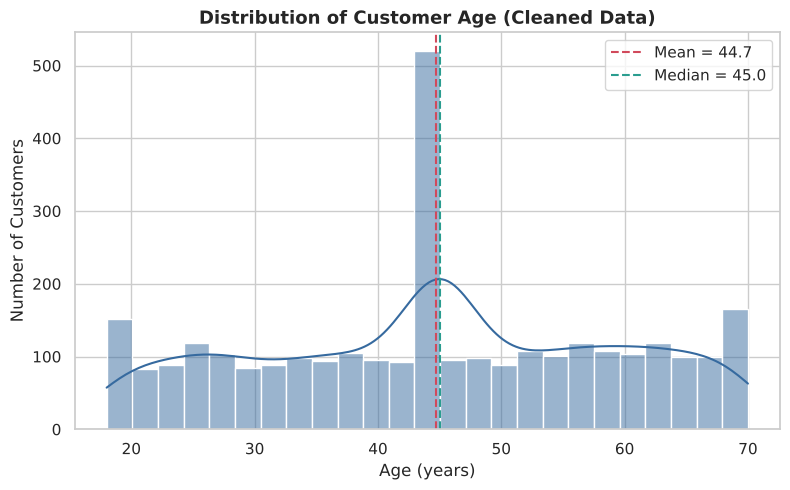

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(demo['Age'], bins=25, kde=True, color=PALETTE[3], ax=ax, edgecolor='white')
ax.axvline(age_summary['mean'], color='#d1495b', linestyle='--', linewidth=1.5, label=f"Mean = {age_summary['mean']:.1f}")
ax.axvline(age_summary['median'], color='#2a9d8f', linestyle='--', linewidth=1.5, label=f"Median = {age_summary['median']:.1f}")
ax.set_title('Distribution of Customer Age (Cleaned Data)', fontsize=13, fontweight='bold')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Number of Customers')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** Age is spread fairly evenly from 18 to 70, with one clear exception: a tall spike exactly at 45, the dataset's median. 427 customers (14.1% of all cleaned rows) have an Age of exactly 45 — far more than any other single age value. This spike is a direct result of the Milestone 1 preprocessing step that filled missing Age values with the column median; it is not a naturally occurring concentration of 45-year-old customers. Outside of that spike, the underlying age distribution looks close to uniform across the adult range, with no other unusual concentration.

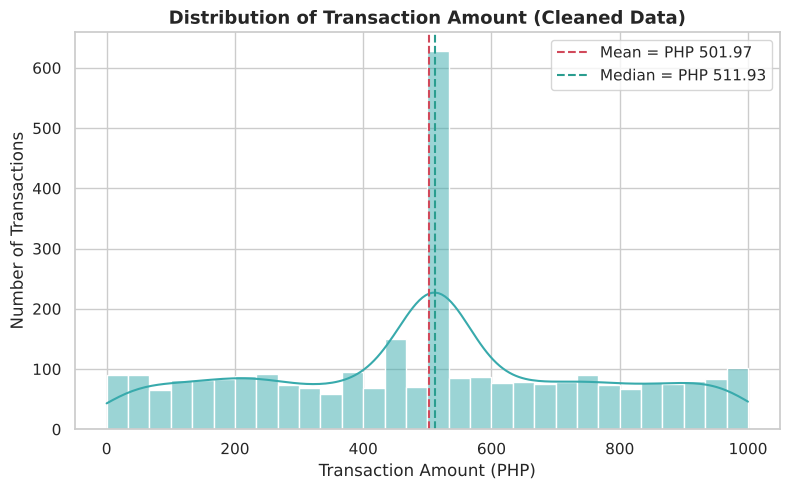

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(trans['Amount'], bins=30, kde=True, color=PALETTE[5], ax=ax, edgecolor='white')
ax.axvline(amount_summary['mean'], color='#d1495b', linestyle='--', linewidth=1.5, label=f"Mean = PHP {amount_summary['mean']:.2f}")
ax.axvline(amount_summary['median'], color='#2a9d8f', linestyle='--', linewidth=1.5, label=f"Median = PHP {amount_summary['median']:.2f}")
ax.set_title('Distribution of Transaction Amount (Cleaned Data)', fontsize=13, fontweight='bold')
ax.set_xlabel('Transaction Amount (PHP)')
ax.set_ylabel('Number of Transactions')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** Transaction Amount shows the same pattern as Age: a visible spike around PHP 511.93, which is the single most common value in the dataset (349 transactions, 11.6% of the cleaned data). This is the category-wise median value used to fill missing Amounts during Milestone 1 preprocessing, so part of the apparent 'concentration' near the center of the distribution reflects the imputation method rather than actual customer spending behavior. Aside from this spike, transaction amounts are spread broadly from PHP 0 to just under PHP 1,000, without a strong concentration at either end.

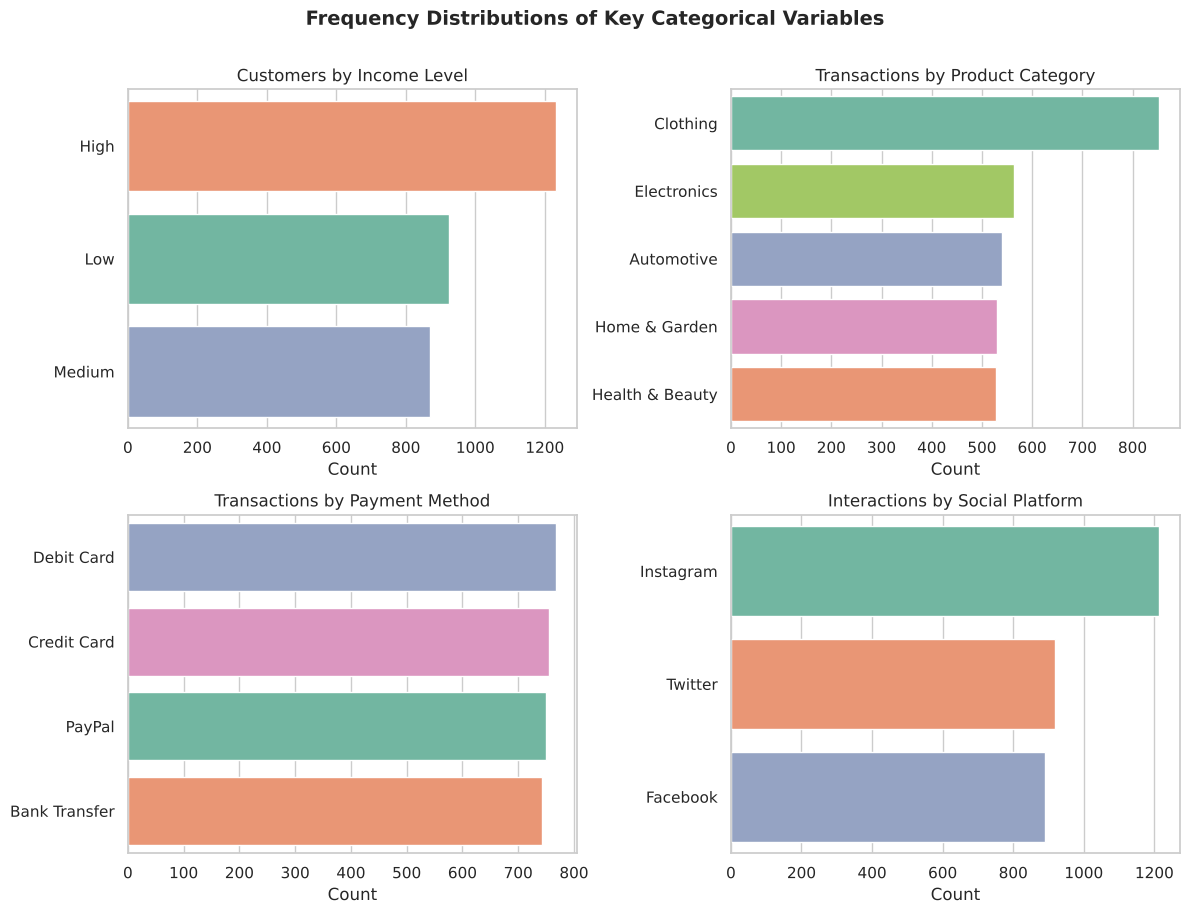

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

order = demo['IncomeLevel'].value_counts().index
sns.countplot(data=demo, y='IncomeLevel', order=order, hue='IncomeLevel', legend=False,
              palette=CAT_PALETTE, ax=axes[0, 0])
axes[0, 0].set_title('Customers by Income Level')
axes[0, 0].set_xlabel('Count')
axes[0, 0].set_ylabel('')

order = trans['ProductCategory'].value_counts().index
sns.countplot(data=trans, y='ProductCategory', order=order, hue='ProductCategory', legend=False,
              palette=CAT_PALETTE, ax=axes[0, 1])
axes[0, 1].set_title('Transactions by Product Category')
axes[0, 1].set_xlabel('Count')
axes[0, 1].set_ylabel('')

order = trans['PaymentMethod'].value_counts().index
sns.countplot(data=trans, y='PaymentMethod', order=order, hue='PaymentMethod', legend=False,
              palette=CAT_PALETTE, ax=axes[1, 0])
axes[1, 0].set_title('Transactions by Payment Method')
axes[1, 0].set_xlabel('Count')
axes[1, 0].set_ylabel('')

order = social['Platform'].value_counts().index
sns.countplot(data=social, y='Platform', order=order, hue='Platform', legend=False,
              palette=CAT_PALETTE, ax=axes[1, 1])
axes[1, 1].set_title('Interactions by Social Platform')
axes[1, 1].set_xlabel('Count')
axes[1, 1].set_ylabel('')

fig.suptitle('Frequency Distributions of Key Categorical Variables', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**Interpretation.** Payment Method and Social Platform are close to evenly split across their categories. Income Level and Product Category each have one clearly leading category (High income; Clothing), consistent with the Milestone 1 finding that these two variables lean toward a dominant value, partly because that same value is also the mode used to fill their missing entries during preprocessing.

## 4. Variable Distributions and Relationships Between Variables

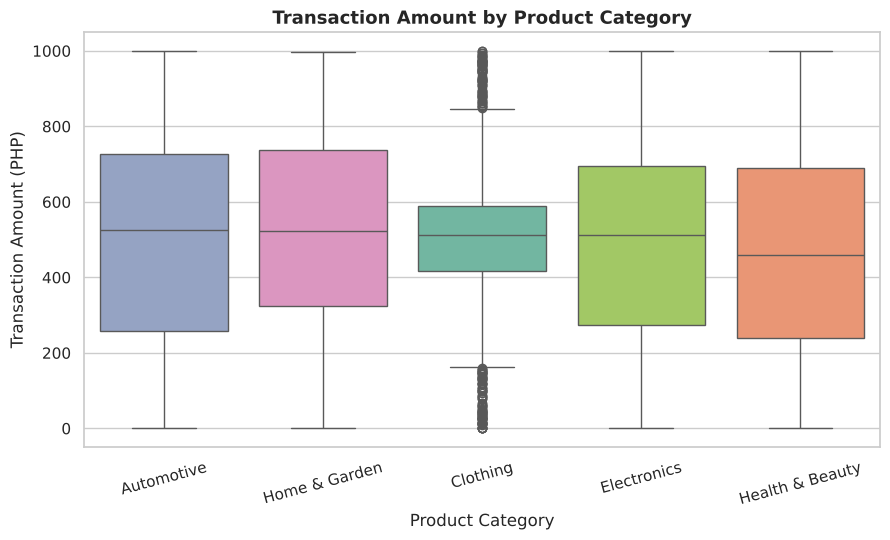

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
order = trans.groupby('ProductCategory')['Amount'].median().sort_values(ascending=False).index
sns.boxplot(data=trans, x='ProductCategory', y='Amount', order=order, hue='ProductCategory',
            legend=False, palette=CAT_PALETTE, ax=ax)
ax.set_title('Transaction Amount by Product Category', fontsize=13, fontweight='bold')
ax.set_xlabel('Product Category')
ax.set_ylabel('Transaction Amount (PHP)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretation.** Median transaction Amount is similar across all five product categories (roughly PHP 420-525), so the categories do not show a large difference in typical spending. Clothing stands out visually, but not because it is more expensive: its box is noticeably narrower than the other four, and it is the only category with points flagged by the plot as statistical outliers (both near 0 and near 1,000). This narrower spread is a side effect of the category-wise median imputation used in Milestone 1 preprocessing — Clothing was the modal ProductCategory, so Amount values could end up grouped there by the fill logic, compressing its spread relative to the other categories. This is a preprocessing artifact to flag for Milestone 2, not a genuine business difference between categories.

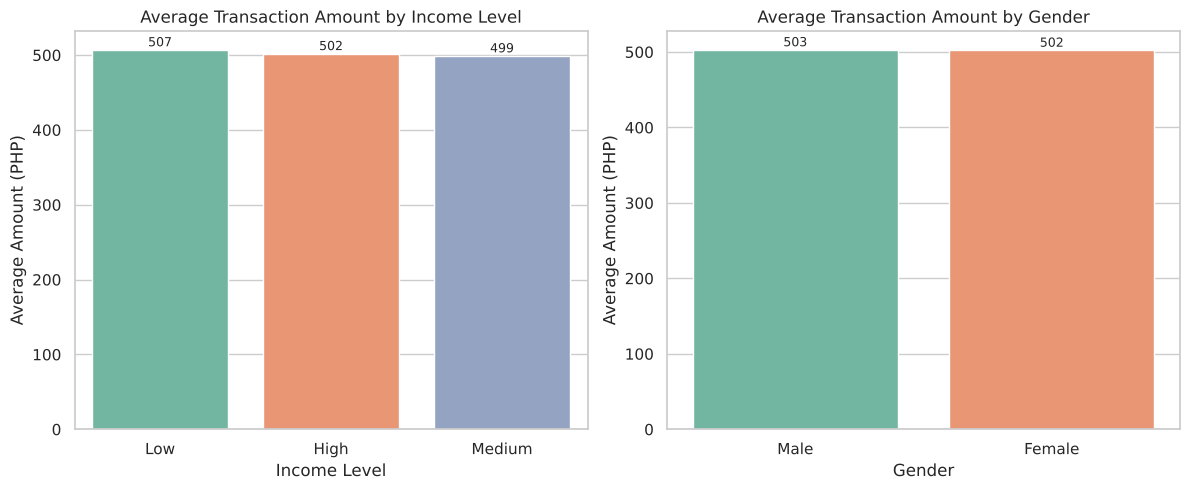

In [9]:
merged = trans.merge(demo, on='CustomerID', how='left')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

income_avg = merged.groupby('IncomeLevel')['Amount'].mean().sort_values(ascending=False)
sns.barplot(x=income_avg.index, y=income_avg.values, hue=income_avg.index, legend=False,
            palette=CAT_PALETTE, ax=axes[0])
axes[0].set_title('Average Transaction Amount by Income Level')
axes[0].set_xlabel('Income Level')
axes[0].set_ylabel('Average Amount (PHP)')
for i, v in enumerate(income_avg.values):
    axes[0].text(i, v + 5, f"{v:.0f}", ha='center', fontsize=9)

gender_avg = merged.groupby('Gender')['Amount'].mean().sort_values(ascending=False)
sns.barplot(x=gender_avg.index, y=gender_avg.values, hue=gender_avg.index, legend=False,
            palette=CAT_PALETTE, ax=axes[1])
axes[1].set_title('Average Transaction Amount by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Average Amount (PHP)')
for i, v in enumerate(gender_avg.values):
    axes[1].text(i, v + 5, f"{v:.0f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

**Interpretation.** Average transaction Amount is nearly identical across Income Level (PHP 499-507) and across Gender (PHP 502-503). These bar charts use a full y-axis starting at 0 so the comparison is not visually exaggerated: the bars are genuinely close in height. This shows no large difference in average spending by income or gender in this dataset. It does not, on its own, establish that spending is statistically independent of these variables — that would require a formal test (e.g., ANOVA or a non-parametric equivalent), which is outside the scope of this descriptive visualization exercise.

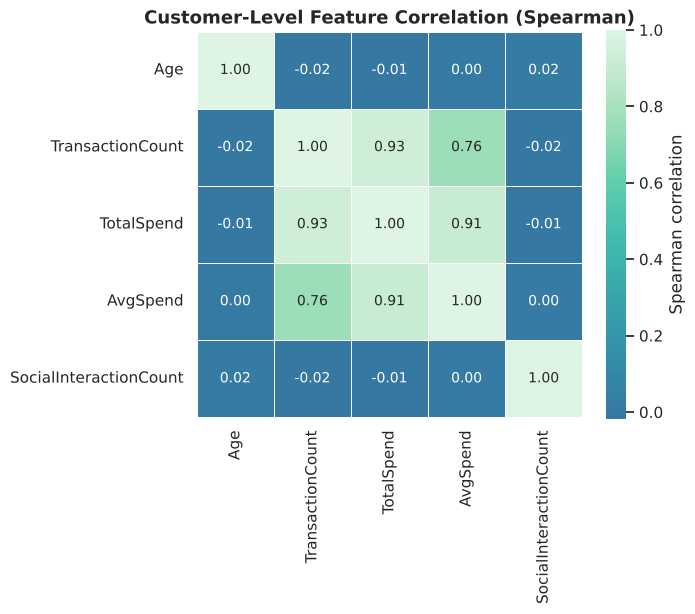

                          Age  TransactionCount  TotalSpend  AvgSpend  SocialInteractionCount
Age                     1.000            -0.018      -0.009     0.001                   0.017
TransactionCount       -0.018             1.000       0.930     0.760                  -0.016
TotalSpend              -0.009            0.930       1.000     0.910                  -0.009
AvgSpend                 0.001            0.760       0.910     1.000                   0.003
SocialInteractionCount   0.017           -0.016      -0.009     0.003                   1.000


In [10]:
tpc_series = trans.groupby('CustomerID').size().rename('TransactionCount')
total_spend = trans.groupby('CustomerID')['Amount'].sum().rename('TotalSpend')
avg_spend = trans.groupby('CustomerID')['Amount'].mean().rename('AvgSpend')
social_count = social.groupby('CustomerID').size().rename('SocialInteractionCount')

cust_features = demo[['CustomerID', 'Age']].merge(tpc_series, on='CustomerID', how='left') \
    .merge(total_spend, on='CustomerID', how='left') \
    .merge(avg_spend, on='CustomerID', how='left') \
    .merge(social_count, on='CustomerID', how='left')
cust_features[['TransactionCount', 'TotalSpend', 'AvgSpend', 'SocialInteractionCount']] = \
    cust_features[['TransactionCount', 'TotalSpend', 'AvgSpend', 'SocialInteractionCount']].fillna(0)

corr = cust_features.drop(columns='CustomerID').corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='mako', center=0, square=True,
            linewidths=0.5, cbar_kws={'label': "Spearman correlation"}, ax=ax)
ax.set_title('Customer-Level Feature Correlation (Spearman)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(corr.round(3))

**Interpretation.** At the customer level, TransactionCount, TotalSpend, and AvgSpend correlate strongly with each other (0.76-0.93), which is expected since they are all derived from the same transaction records (a customer who buys more often naturally tends to spend more in total). Age and SocialInteractionCount, by contrast, show essentially no correlation with any of the spending measures (all values between -0.02 and 0.02). This suggests that, in this dataset, a customer's age and how often they engage on social media show no observed linear or rank-based relationship with how much or how often they buy. As with the income/gender comparison above, this is a descriptive observation from the available data, not proof that no relationship exists.

## 5. Trends or Patterns Over Time

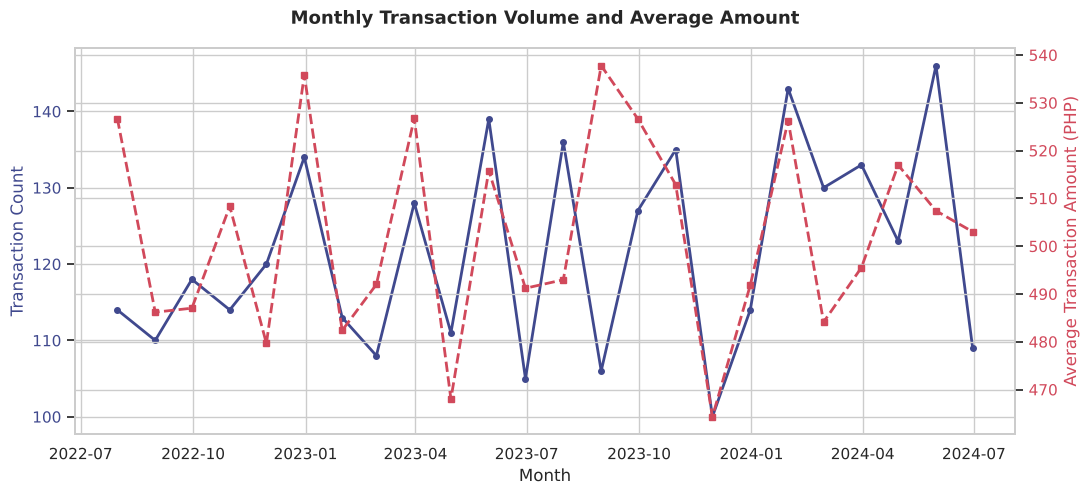

In [11]:
trans_monthly = trans.set_index('TransactionDate').resample('ME').agg(
    TransactionCount=('Amount', 'size'),
    AvgAmount=('Amount', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(trans_monthly['TransactionDate'], trans_monthly['TransactionCount'],
         color=PALETTE[2], marker='o', markersize=4, linewidth=2, label='Transaction Count')
ax1.set_xlabel('Month')
ax1.set_ylabel('Transaction Count', color=PALETTE[2])
ax1.tick_params(axis='y', labelcolor=PALETTE[2])

ax2 = ax1.twinx()
ax2.plot(trans_monthly['TransactionDate'], trans_monthly['AvgAmount'],
         color='#d1495b', marker='s', markersize=4, linewidth=2, linestyle='--', label='Average Amount')
ax2.set_ylabel('Average Transaction Amount (PHP)', color='#d1495b')
ax2.tick_params(axis='y', labelcolor='#d1495b')

fig.suptitle('Monthly Transaction Volume and Average Amount', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

**Interpretation.** Monthly transaction count fluctuates between roughly 100 and 150 transactions across the two-year window (July 2022-June 2024), without a clear long-term upward or downward trend — the variation looks closer to noise than to a sustained growth or decline pattern. Average transaction amount also moves within a fairly narrow band (roughly PHP 470-535) with no obvious seasonal cycle (e.g., no consistent spike around specific months). This is useful for future ML work: it suggests that, at a monthly aggregate level, there is no strong time-based signal (trend or seasonality) in this transaction data that a model would need to account for.

## 6. Dominant Categories or Imbalances

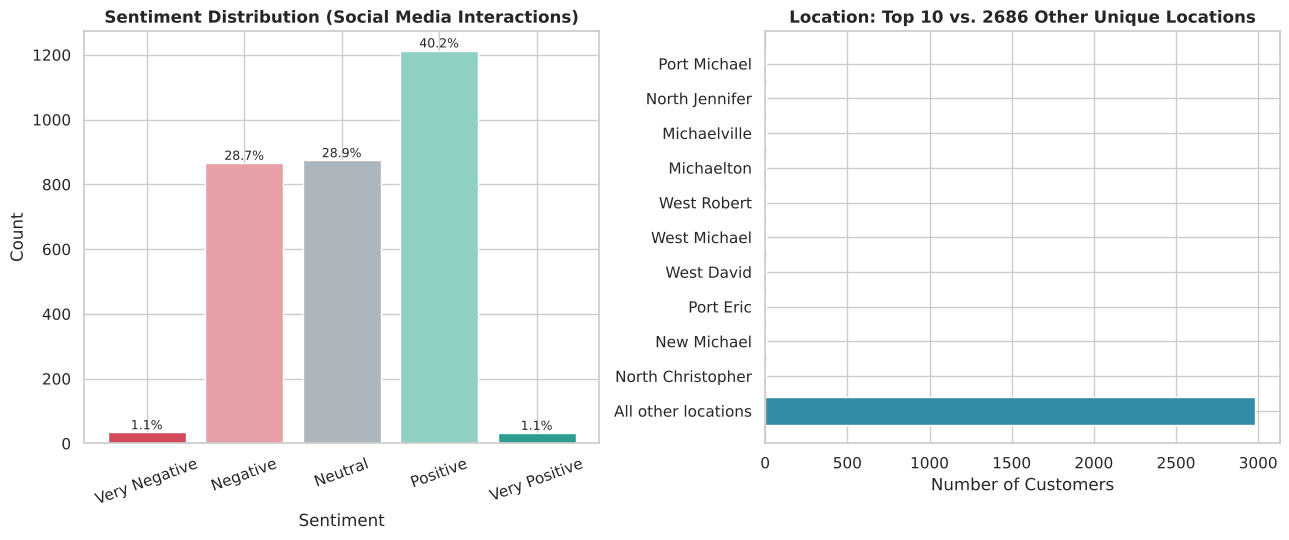

Location cardinality: 2696 unique values across 3023 rows
Sentiment share - Very Positive + Very Negative: 2.19%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sentiment_order = ['Very Negative', 'Negative', 'Neutral', 'Positive', 'Very Positive']
sentiment_counts = social['Sentiment'].value_counts().reindex(sentiment_order)
colors = ['#d1495b', '#e8a0a8', '#adb5bd', '#8fd0c4', '#2a9d8f']
bars = axes[0].bar(sentiment_counts.index, sentiment_counts.values, color=colors, edgecolor='white')
axes[0].set_title('Sentiment Distribution (Social Media Interactions)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=20)
for bar in bars:
    h = bar.get_height()
    pct = h / sentiment_counts.sum() * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 10, f"{pct:.1f}%", ha='center', fontsize=9)

loc_counts = demo['Location'].value_counts()
top_n = 10
top_locations = loc_counts.head(top_n)
other_count = loc_counts.iloc[top_n:].sum()
loc_display = pd.concat([top_locations, pd.Series({'All other locations': other_count})])
axes[1].barh(loc_display.index[::-1], loc_display.values[::-1], color=PALETTE[4], edgecolor='white')
axes[1].set_title(f'Location: Top {top_n} vs. {loc_counts.shape[0]-top_n} Other Unique Locations',
                   fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Customers')

plt.tight_layout()
plt.show()

print(f"Location cardinality: {demo['Location'].nunique()} unique values across {demo.shape[0]} rows")
print(f"Sentiment share - Very Positive + Very Negative: "
      f"{(sentiment_counts[['Very Positive','Very Negative']].sum() / sentiment_counts.sum() * 100):.2f}%")

**Interpretation.** Sentiment is the most imbalanced categorical variable in the dataset: Positive, Neutral, and Negative together make up 97.8% of records, while 'Very Positive' and 'Very Negative' combined make up only 2.19%. A classifier trained to predict Sentiment as-is would see very few examples of the two 'Very' classes and could effectively ignore them unless class weighting or resampling is applied at modeling time. Location shows an even more extreme form of imbalance: with 2,696 distinct values across 3,023 customers, almost every customer has a unique or near-unique location, and even the 10 most common locations have only 4-5 customers each next to nearly 3,000 customers spread across the remaining values. This makes Location unusable as a direct categorical feature without first grouping it into broader regions.

## 7. Outliers or Unusual Observations

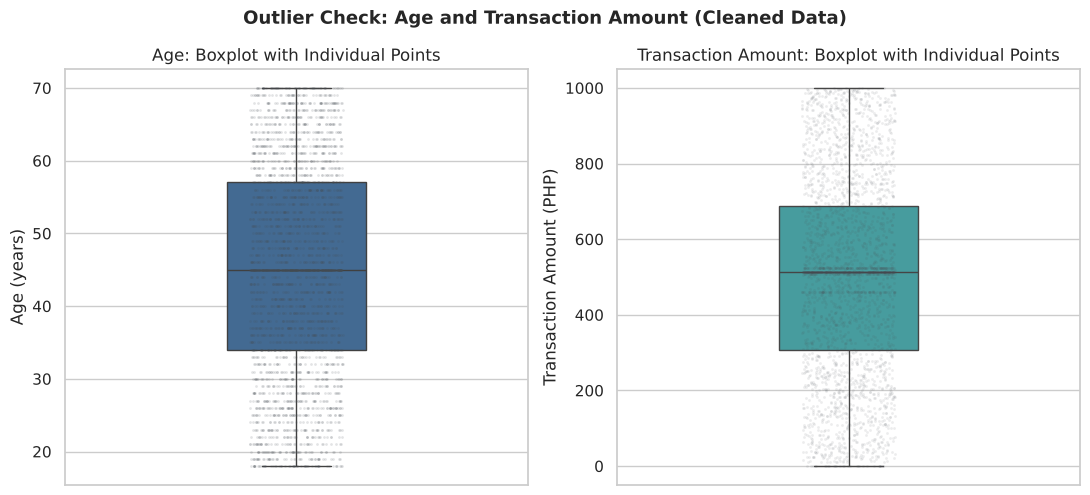

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

sns.boxplot(y=demo['Age'], color=PALETTE[3], ax=axes[0], width=0.3)
sns.stripplot(y=demo['Age'], color='#495057', alpha=0.15, size=2, ax=axes[0])
axes[0].set_title('Age: Boxplot with Individual Points')
axes[0].set_ylabel('Age (years)')

sns.boxplot(y=trans['Amount'], color=PALETTE[5], ax=axes[1], width=0.3)
sns.stripplot(y=trans['Amount'], color='#495057', alpha=0.1, size=2, ax=axes[1])
axes[1].set_title('Transaction Amount: Boxplot with Individual Points')
axes[1].set_ylabel('Transaction Amount (PHP)')

fig.suptitle('Outlier Check: Age and Transaction Amount (Cleaned Data)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [14]:
def iqr_outlier_count(series):
    q1, q3 = np.percentile(series, [25, 75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lo) | (series > hi)).sum(), lo, hi

age_out, age_lo, age_hi = iqr_outlier_count(demo['Age'])
amt_out, amt_lo, amt_hi = iqr_outlier_count(trans['Amount'])
print(f"IQR outlier bounds - Age: [{age_lo:.1f}, {age_hi:.1f}] -> {age_out} flagged")
print(f"IQR outlier bounds - Amount: [{amt_lo:.1f}, {amt_hi:.1f}] -> {amt_out} flagged")

zero_amount_count = (trans['Amount'] == 0).sum()
print(f"Transactions with Amount == 0: {zero_amount_count}")

IQR outlier bounds - Age: [-0.5, 91.5] -> 0 flagged
IQR outlier bounds - Amount: [-266.2, 1259.3] -> 0 flagged
Transactions with Amount == 0: 29


**Interpretation.** Neither Age nor Amount has any values flagged by the standard 1.5x IQR rule in the cleaned data — consistent with the z-score check in Section 2 and with the Milestone 1 range-validation step having already removed the implausible Age values (previously -1 and 150) and negative Amount values (previously -100). The one remaining unusual observation is a cluster of 29 transactions with an Amount of exactly PHP 0. These are not flagged as statistical outliers since 0 sits within the normal range of the distribution, but they are still worth a closer look before Milestone 2 — a PHP 0 transaction could represent a free item, a promotion, a refund recorded as a transaction, or a data entry issue, and each of those would need to be handled differently in a predictive model.

## 8. Summary of Observations for Milestone 2

- **Age and Amount** are both close to symmetric with no remaining statistical outliers, but each shows a visible spike at its imputed fill value (Age = 45 in 14.1% of rows; Amount = PHP 511.93 in 11.6% of rows). This is an artifact of median imputation, not a natural pattern in customer behavior, and should be kept in mind when this data is used for modeling.
- **Clothing's unusually narrow Amount spread** in the boxplot traces back to the same imputation mechanism and is flagged here as something to revisit, rather than treated as a genuine category-level pricing difference.
- **Spending shows no large difference** by Income Level or Gender, and customer-level correlations between Age, social engagement, and spending measures are all close to zero — useful negative findings, but based on descriptive comparisons rather than formal statistical tests.
- **Sentiment (2.19% 'Very' classes) and Location (2,696 unique values) are the two most imbalanced/high-cardinality variables** and will need class-balancing and regional grouping, respectively, before they can be used effectively in a model.
- **29 zero-value transactions** and the monthly trend's lack of a clear pattern are both noted as items for the team to confirm with further investigation or with FinMark directly, rather than as settled conclusions.